[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/03-math-for-ai/notebooks/01-vectors-and-similarity.ipynb)

# 01 · Vectors, dot product and cosine similarity

**What you will learn**
- a **vector** is a list of numbers *and* an arrow
- adding and scaling vectors, and a vector's **length**
- the **dot product** ("multiply matching pairs, then add") and what its sign means
- **cosine similarity**, the number behind semantic search and RAG
- a first look at **embeddings** with toy word vectors

Intuition only: no proofs. Run each cell with Shift + Enter.

## 0. Setup

We import NumPy (arrays) and matplotlib (charts), and set a few colours.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)   # print numbers neatly
NAVY, TEAL, RED, ORANGE = "#1B263B", "#0F9D9A", "#D1495B", "#F28C28"   # course colours

## 1. A vector is a list of numbers

A house described by `[bedrooms, bathrooms, area in 100 sq ft]`. Each position always means the same thing. The number of entries is the vector's **dimension**.

In [2]:
house = np.array([3, 2, 14])
print("vector:", house, "| dimension:", house.size)

vector: [ 3  2 14] | dimension: 3


## 2. …and an arrow

A 2-D vector `[3, 2]` is an arrow from `(0, 0)` to the point `(3, 2)`. `quiver` draws arrows; the extra arguments make the arrow lengths match the axis units.

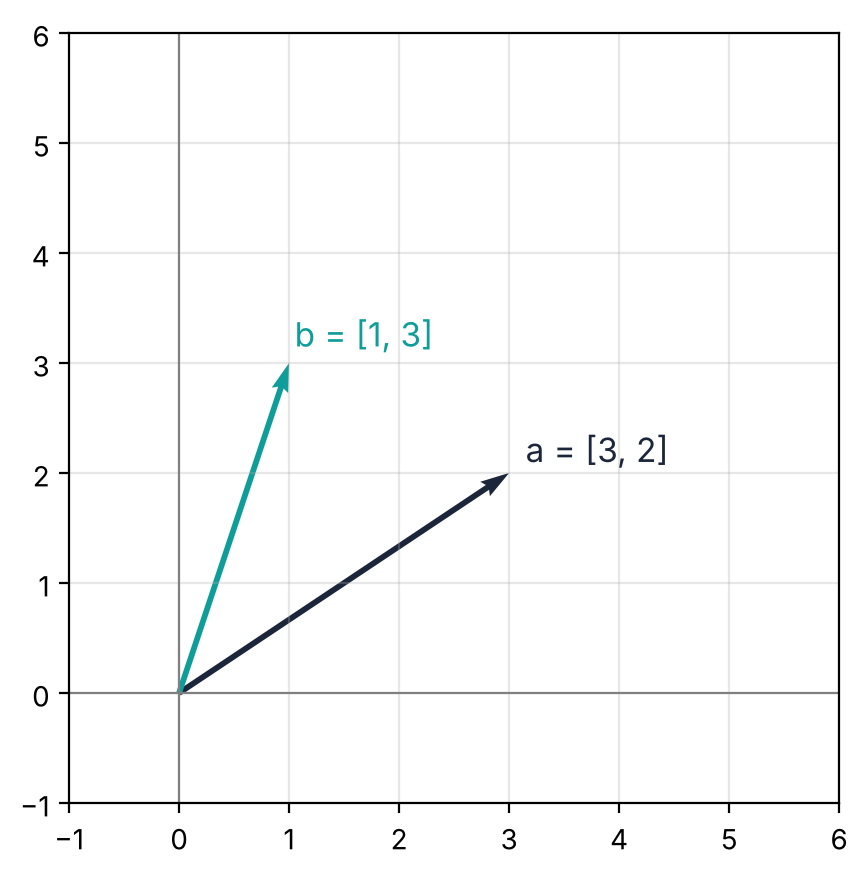

In [3]:
a = np.array([3, 2])
b = np.array([1, 3])

def draw(vectors, colors, labels, lim=6):
    fig, ax = plt.subplots(figsize=(5, 5))
    for v, c, l in zip(vectors, colors, labels):
        ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1, color=c)
        ax.text(v[0] * 1.05, v[1] * 1.05, l, color=c, fontsize=12)
    ax.set_xlim(-1, lim); ax.set_ylim(-1, lim); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
    plt.show()

draw([a, b], [NAVY, TEAL], ["a = [3, 2]", "b = [1, 3]"])

## 3. Adding and scaling

Adding adds matching entries (as arrows: tip to tail). Multiplying by a single number (a **scalar**) stretches the arrow; a negative number flips it.

a + b  = [4 5]
2 * a  = [6 4]
-1 * a = [-3 -2]


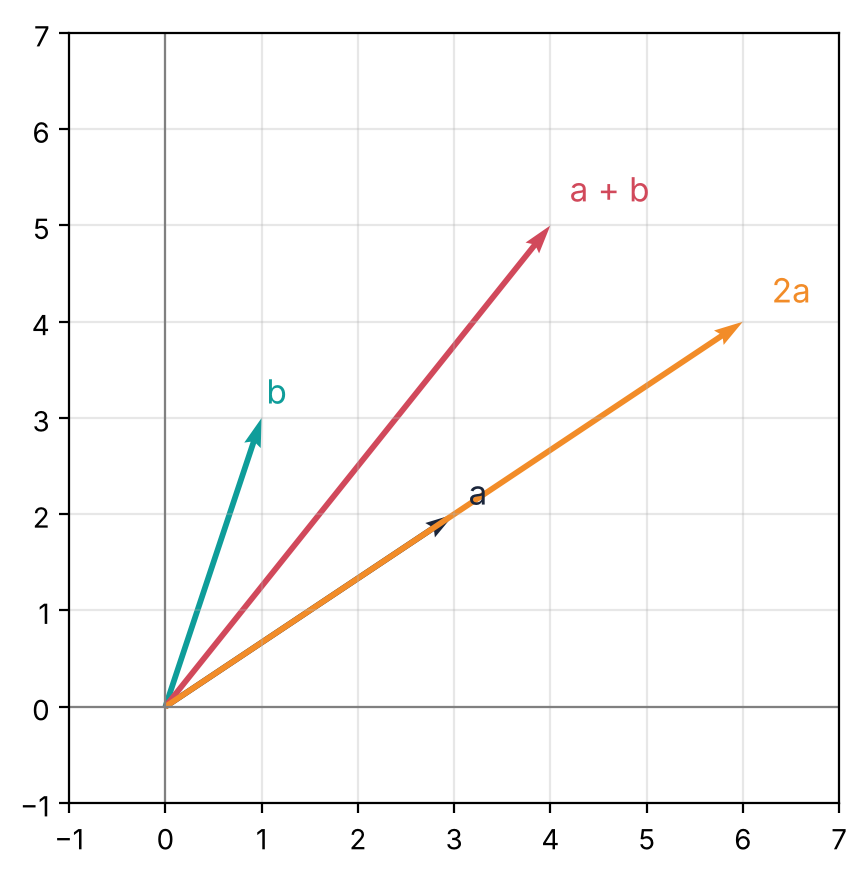

In [4]:
print("a + b  =", a + b)
print("2 * a  =", 2 * a)
print("-1 * a =", -1 * a)
draw([a, b, a + b, 2 * a], [NAVY, TEAL, RED, ORANGE], ["a", "b", "a + b", "2a"], lim=7)

## 4. Length (magnitude, norm)

Length = square every entry, add, take the square root (Pythagoras). `np.linalg.norm` does it for us.

In [5]:
v = np.array([3, 4])
by_hand = np.sqrt((v ** 2).sum())
print("by hand:", by_hand, "| numpy:", np.linalg.norm(v))

by hand: 5.0 | numpy: 5.0


## 5. The dot product: multiply pairs, then add

Shopping bill: quantities `[2, 1, 3]` times prices `[799, 2499, 249]`, all added up. Three ways to write it give the same single number.

In [6]:
qty = np.array([2, 1, 3])
price = np.array([799, 2499, 249])

print("pairs multiplied:", qty * price)
print("summed by hand:  ", (qty * price).sum())
print("np.dot:          ", np.dot(qty, price))
print("@ operator:      ", qty @ price)

pairs multiplied: [1598 2499  747]
summed by hand:   4844
np.dot:           4844
@ operator:       4844


## 6. What the sign of the dot product means

Positive = arrows point a similar way, zero = right angle (unrelated), negative = roughly opposite.

In [7]:
a = np.array([3, 1])
for name, b in [("similar", np.array([2.5, 1.5])), ("right angle", np.array([-1, 3])), ("opposite", np.array([-2.5, -1.2]))]:
    print(f"{name:12s} a · b = {a @ b:6.2f}")

similar      a · b =   9.00
right angle  a · b =   0.00
opposite     a · b =  -8.70


## 7. A weighted sum is a dot product (a tiny "neuron")

Final grade = 0.5 × exam + 0.3 × project + 0.2 × homework. The weights say how important each input is. A neuron in a neural network does exactly this.

In [8]:
weights = np.array([0.5, 0.3, 0.2])
student = np.array([80, 90, 70])     # exam, project, homework
print("final grade:", student @ weights)

final grade: 81.0


## 8. Cosine similarity

The raw dot product grows with length. **Cosine similarity** divides by both lengths, so only the *direction* counts. Result: −1 (opposite) … 0 (unrelated) … +1 (same direction).

In [9]:
def cosine_similarity(u, v):
    return (u @ v) / (np.linalg.norm(u) * np.linalg.norm(v))

u = np.array([1, 2])
print("u vs 10u (longer, same direction):", round(cosine_similarity(u, 10 * u), 3))
print("u vs perpendicular:               ", round(cosine_similarity(u, np.array([-2, 1])), 3))
print("u vs -u:                          ", round(cosine_similarity(u, -u), 3))
print("dot product u·10u (grows with length):", u @ (10 * u))

u vs 10u (longer, same direction): 1.0
u vs perpendicular:                0.0
u vs -u:                           -1.0
dot product u·10u (grows with length): 50


## 9. Toy embeddings

An **embedding** is a vector that represents meaning. Real ones have hundreds of numbers learned by a model. Here we hand-make 4-number "embeddings" with features we can read:
`[is_animal, is_vehicle, size, is_pet]`. That makes it easy to see *why* two words are similar.

In [10]:
words = {
    "cat":   np.array([1.0, 0.0, 0.2, 1.0]),
    "dog":   np.array([1.0, 0.0, 0.4, 1.0]),
    "lion":  np.array([1.0, 0.0, 0.7, 0.0]),
    "car":   np.array([0.0, 1.0, 0.5, 0.0]),
    "truck": np.array([0.0, 1.0, 0.9, 0.0]),
    "bike":  np.array([0.0, 0.8, 0.2, 0.1]),
}
names = list(words)
sim = np.array([[cosine_similarity(words[a], words[b]) for b in names] for a in names])
print(np.round(sim, 2))

[[1.   0.99 0.65 0.06 0.09 0.12]
 [0.99 1.   0.71 0.12 0.18 0.15]
 [0.65 0.71 1.   0.26 0.38 0.14]
 [0.06 0.12 0.26 1.   0.96 0.97]
 [0.09 0.18 0.38 0.96 1.   0.88]
 [0.12 0.15 0.14 0.97 0.88 1.  ]]


## 10. Similarity as a heatmap

Bright squares = similar meaning. Animals form one bright block, vehicles another.

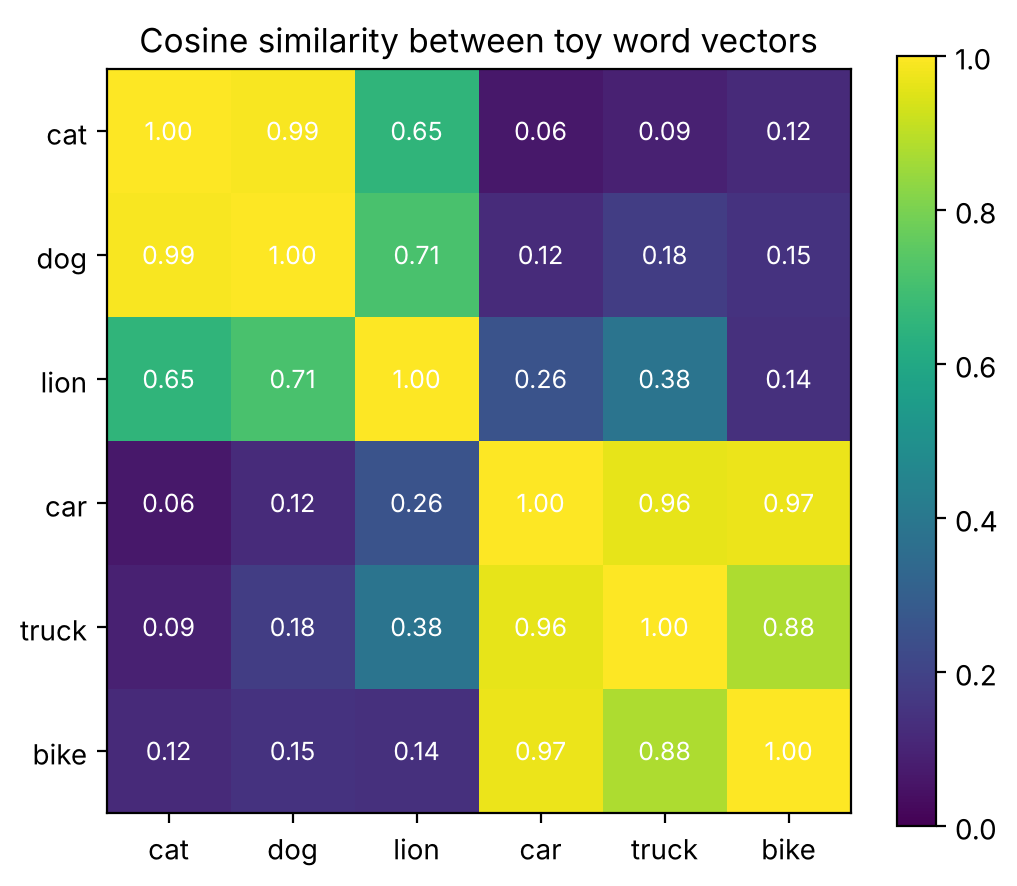

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)
ax.set_title("Cosine similarity between toy word vectors")
fig.colorbar(im); plt.show()

## 11. A tiny "semantic search"

Given a query vector, rank every word by cosine similarity. This is exactly what a vector database does in RAG (Module 09), only with millions of real embeddings. Our query: "a big pet-like animal".

In [12]:
query = np.array([1.0, 0.0, 0.8, 0.5])
ranked = sorted(names, key=lambda w: cosine_similarity(query, words[w]), reverse=True)
for w in ranked:
    print(f"{w:6s} {cosine_similarity(query, words[w]):.3f}")

lion   0.930
dog    0.901
cat    0.845
truck  0.389
car    0.260
bike   0.184


## 12. Real embeddings (preview)

In Modules 06 and 09 you will get real embeddings from a model such as `sentence-transformers/all-MiniLM-L6-v2` (384 numbers per sentence). The code looks like this; we do not run it here to keep this notebook offline and fast:

```python
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
vecs = model.encode(["I love my cat", "My kitten is adorable", "The truck broke down"])
# cosine_similarity(vecs[0], vecs[1]) is high, cosine_similarity(vecs[0], vecs[2]) is low
```

## Your turn

1. Add a word `"puppy"` to `words` and check it is most similar to `"dog"`.
2. Make a query for "a small vehicle" and print the top 2 words.

## Recap
Vector = list = arrow. Dot product = multiply pairs and add; sign shows alignment. Cosine similarity = dot product ÷ lengths, from −1 to +1; it compares meaning between embeddings.